# 决策树

### 问题

前面两个模型都是线性的,边界是一条直线。决策树不一样:它不停地问某个特征是不是大于某个值,把空间切成一个个小方块,每个方块给一个类别。

一个节点要不要分裂、按哪个特征哪个阈值分,靠的是不纯度。最常用的是基尼指数:

$$Gini=1-\sum_{k}p_k^2$$

p_k 是当前节点里第 k 类占的比例。全是同一类时 Gini 是 0,各类均分时最大。分裂后把两边的 Gini 按样本数加权平均,挑加权 Gini 最小的那种分法。

## 1. 数据

鸢尾花数据,150 条,4 个特征(萼片和花瓣的长宽),3 个类别。留 30% 做测试。

In [1]:
import warnings
import numpy as np
import matplotlib.pyplot as plt

# 本机 numpy 2.0 会对 matmul 误报浮点警告,结果是对的
warnings.filterwarnings("ignore", message=".*in matmul")

# 中文和负号
plt.rcParams["font.sans-serif"] = ["Arial Unicode MS"]
plt.rcParams["axes.unicode_minus"] = False

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

iris = load_iris()
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0, stratify=y)

print(X_train.shape, X_test.shape)
print(iris.feature_names)

(105, 4) (45, 4)
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


## 2. 手算一次分裂

只在花瓣长度这一个特征上扫一遍所有可能的切点,看哪个切点最纯。

In [2]:
def gini(labels):
    p = np.bincount(labels, minlength=3) / len(labels)
    return 1 - (p ** 2).sum()

print("不分裂时的 gini:", round(gini(y_train), 4))

feature = X_train[:, 2]
best = None
for t in np.unique(feature)[:-1]:
    left, right = y_train[feature <= t], y_train[feature > t]
    score = (len(left) * gini(left) + len(right) * gini(right)) / len(feature)
    if best is None or score < best[0]:
        best = (score, t)

print("最好的切点:", round(best[1], 2), "加权 gini:", round(best[0], 4))

不分裂时的 gini: 0.6667
最好的切点: 1.7 加权 gini: 0.3333


gini 从 0.6667 掉到 0.3333,而且切点 1.7 正好把 setosa 完全分到左边,左边的 gini 是 0。

打开 sklearn 训好的树会发现根节点用的是花瓣宽度 0.8,不是花瓣长度 1.7。两种分法算出来的加权 gini 都是 0.3333,只是把同一批 setosa 切出去了,所以谁先被扫到就用谁。

## 3. 训练一棵树

先限制深度为 3。不加限制的话它会一直分到每个叶子只有一类,后面会看到那样的问题。

In [3]:
tree = DecisionTreeClassifier(max_depth=3, random_state=0).fit(X_train, y_train)

print("叶子数", tree.get_n_leaves(), "深度", tree.get_depth())
print("train", round(tree.score(X_train, y_train), 4))
print("test ", round(tree.score(X_test, y_test), 4))

叶子数 5 深度 3
train 0.9619
test  0.9556


训练集 0.9619,测试集 0.9556,45 个测试样本里错 2 个。树的深度其实是 3,但因为一条分支提前停了,只有 5 个叶子。

## 4. 树长什么样

`plot_tree` 可以把整棵树画出来。

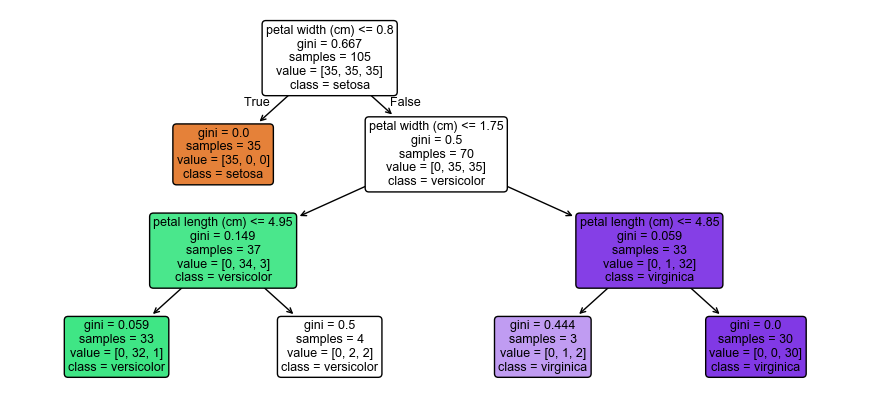

In [4]:
from sklearn.tree import plot_tree

fig, ax = plt.subplots(figsize=(11, 5))
plot_tree(tree, feature_names=iris.feature_names, class_names=iris.target_names,
          filled=True, rounded=True, fontsize=9, ax=ax)
plt.show()

每个框里四行:分裂条件、gini、样本数、各类计数。颜色越深说明那一类占比越高。

看根节点:花瓣宽度小于等于 0.8 的都往左走,35 个样本全是 setosa,gini 是 0,直接就停了。往右的 70 个还要继续分,因为 versicolor 和 virginica 混在一起。

## 5. 决策边界

只用花瓣长和花瓣宽两个特征再训一棵,把平面涂色看看切出来的形状。

两特征训练集: 0.9905 测试集: 0.9778


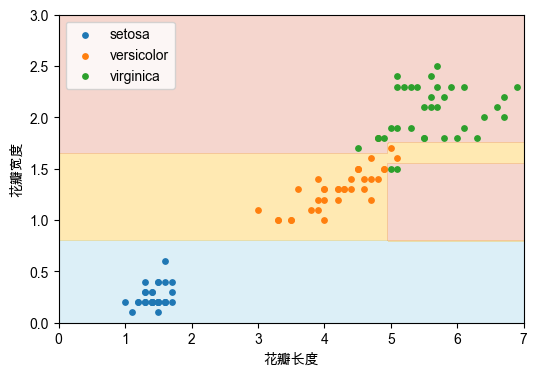

In [5]:
X2 = X[:, [2, 3]]
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y, test_size=0.3, random_state=0, stratify=y)

tree2 = DecisionTreeClassifier(max_depth=4, random_state=0).fit(X2_train, y2_train)
print("两特征训练集:", round(tree2.score(X2_train, y2_train), 4),
      "测试集:", round(tree2.score(X2_test, y2_test), 4))

xx, yy = np.meshgrid(np.linspace(0, 7, 300), np.linspace(0, 3, 300))
Z = tree2.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

fig, ax = plt.subplots(figsize=(6, 4))
ax.contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5, 2.5],
            colors=["#8ecae6", "#ffb703", "#e07a5f"], alpha=0.3)

for k, name in enumerate(iris.target_names):
    mask = y2_train == k
    ax.scatter(X2_train[mask, 0], X2_train[mask, 1], s=15, label=name)

ax.set_xlabel("花瓣长度")
ax.set_ylabel("花瓣宽度")
ax.legend()
plt.show()

边界全是水平和竖直线段,因为每个节点只在一个特征上切一刀。这也是树的缺点,数据要是斜着排,它得用很多个台阶去逼近,而逻辑回归一条斜线就解决了。

正因为只比大小,树不需要标准化,把特征乘个系数或者加个常数,分裂结果完全一样。

## 6. 特征重要性

`feature_importances_` 统计每个特征参与分裂时降低了多少不纯度,再归一化到加起来等于 1。

In [6]:
for name, imp in zip(iris.feature_names, tree.feature_importances_):
    print(f"{name:<25} {imp:.3f}")

sepal length (cm)         0.000
sepal width (cm)          0.000
petal length (cm)         0.034
petal width (cm)          0.966


花瓣宽度 0.966,花瓣长度 0.034,两个萼片特征一次都没用上。setosa 靠花瓣宽度就能分出来,剩下的 versicolor 和 virginica 主要差在花瓣宽度上。

这个指标有个坑:它偏向取值多的连续特征,而且是在训练集上算的。真要比较特征重要性,最好用置换重要性或者换随机森林看。

## 7. 深度和过拟合

iris 数据太干净,树长到 4 层就不长了。换成一份有噪声的数据:两个半月形,加了 0.35 的噪声。

In [7]:
from sklearn.datasets import make_moons

X_m, y_m = make_moons(n_samples=400, noise=0.35, random_state=0)
X_m_train, X_m_test, y_m_train, y_m_test = train_test_split(
    X_m, y_m, test_size=0.3, random_state=0, stratify=y_m)

print(X_m_train.shape, X_m_test.shape)

(280, 2) (120, 2)


In [8]:
depths = list(range(1, 16))
train_scores, test_scores = [], []

for d in depths:
    t = DecisionTreeClassifier(max_depth=d, random_state=0).fit(X_m_train, y_m_train)
    train_scores.append(t.score(X_m_train, y_m_train))
    test_scores.append(t.score(X_m_test, y_m_test))

for d, tr, te in zip(depths, train_scores, test_scores):
    print(f"depth={d:<2} train={tr:.3f} test={te:.3f}")

depth=1  train=0.793 test=0.833
depth=2  train=0.886 test=0.892
depth=3  train=0.886 test=0.892
depth=4  train=0.889 test=0.892
depth=5  train=0.904 test=0.825
depth=6  train=0.918 test=0.783
depth=7  train=0.939 test=0.808
depth=8  train=0.961 test=0.800
depth=9  train=0.971 test=0.800
depth=10 train=0.979 test=0.792
depth=11 train=0.993 test=0.775
depth=12 train=0.993 test=0.775
depth=13 train=0.996 test=0.792
depth=14 train=1.000 test=0.792
depth=15 train=1.000 test=0.792


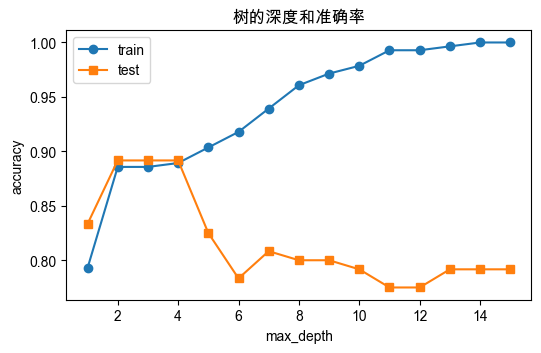

In [9]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(depths, train_scores, marker="o", label="train")
ax.plot(depths, test_scores, marker="s", label="test")
ax.set_xlabel("max_depth")
ax.set_ylabel("accuracy")
ax.set_title("树的深度和准确率")
ax.legend()
plt.show()

训练集一路涨到 1.0,测试集在第 2 到 4 层是 0.892,再深就掉到 0.792。树把噪声点也一个个记住了,边界被切成很多细碎的小方块,换一批数据就不灵了。

这就是过拟合在树上的样子:模型复杂度上去了,训练集满分,测试集反而退步。

## 8. 后剪枝

提前限深度是个办法,另一种是先把树长满,再按代价复杂度剪回去。`ccp_alpha` 越大剪得越狠。

sklearn 可以先用 `cost_complexity_pruning_path` 拿到一串候选 alpha,再逐个试。

In [10]:
path = DecisionTreeClassifier(random_state=0).cost_complexity_pruning_path(X_m_train, y_m_train)
alphas = path.ccp_alphas[:-1]     # 最后一个 alpha 只剩一个叶子,没意义

results = []
for a in alphas:
    t = DecisionTreeClassifier(ccp_alpha=a, random_state=0).fit(X_m_train, y_m_train)
    results.append((a, t.get_n_leaves(), t.score(X_m_train, y_m_train), t.score(X_m_test, y_m_test)))

best = max(results, key=lambda r: r[3])
print("alpha", round(best[0], 4), "叶子", best[1], "train", round(best[2], 3), "test", round(best[3], 3))
print("不剪枝的树 test:", round(test_scores[-1], 3), "叶子", DecisionTreeClassifier(random_state=0).fit(X_m_train, y_m_train).get_n_leaves())

alpha 0.0069 叶子 7 train 0.886 test 0.892
不剪枝的树 test: 0.792 叶子 47


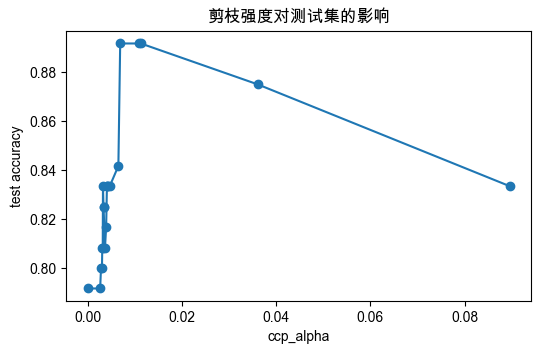

In [11]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot([r[0] for r in results], [r[3] for r in results], marker="o")
ax.set_xlabel("ccp_alpha")
ax.set_ylabel("test accuracy")
ax.set_title("剪枝强度对测试集的影响")
plt.show()

不剪枝 47 个叶子,test 0.792;剪到 alpha=0.0069 只剩 7 个叶子,test 回到 0.892。二十多个叶子里大部分在记噪声,剪掉反而更好。

实际调参时不用手算,`GridSearchCV` 里把 `ccp_alpha` 当成一个参数搜就行。

## 9. 回归树

决策树也能做回归:叶子不投票,而是取落在叶子里的样本均值,所以输出是阶梯状的。

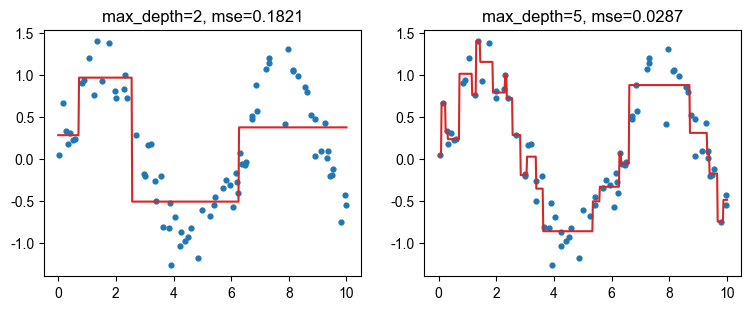

In [12]:
rng = np.random.default_rng(0)
x_r = np.sort(rng.uniform(0, 10, 80))
y_r = np.sin(x_r) + rng.normal(0, 0.25, 80)

from sklearn.tree import DecisionTreeRegressor

xs = np.linspace(0, 10, 500).reshape(-1, 1)
fig, axs = plt.subplots(1, 2, figsize=(9, 3.2))

for ax, d in zip(axs, [2, 5]):
    reg = DecisionTreeRegressor(max_depth=d, random_state=0).fit(x_r.reshape(-1, 1), y_r)
    mse = np.mean((y_r - reg.predict(x_r.reshape(-1, 1))) ** 2)
    ax.scatter(x_r, y_r, s=12)
    ax.plot(xs, reg.predict(xs), color="tab:red")
    ax.set_title(f"max_depth={d}, mse={mse:.4f}")

plt.show()

深度 2 只有 4 个台阶,mse 0.18,只能看出大致趋势;深度 5 有 26 个台阶,mse 0.029,开始跟着噪声上下跳。回归树一样有过拟合的问题,而且它永远画不出光滑曲线。

## 10. 小结

- 树的分裂只看不纯度下降,不需要标准化,也不用管特征之间是否线性相关;
- 边界是轴对齐的矩形,遇到斜着分布的数据要靠多切几刀来逼近;
- 深度或者叶子数不限制一定会过拟合,iris 这种干净数据看不出来,换个有噪声的立刻现形;
- 后剪枝用 `ccp_alpha`,不剪枝 47 个叶子 test 0.792,剪到 7 个叶子升到 0.892;
- `feature_importances_` 是训练集上的不纯度下降,偏向连续特征,别当成因果解释。